# Customer Transection Prediction using Machine Learning

## Importing Required Libraries

In [1]:
# Import Requried Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnin message
import warnings
warnings.filterwarnings("ignore")

# Import preprocessing library
from sklearn.preprocessing import StandardScaler

# Import Machine Learning Models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Import evaluation metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

# Import library to save model
import joblib

## Loading the Dataset

In [2]:
# Load Dataset
df = pd.read_csv("train(1).csv")

# Display first five rows
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [3]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001
199999,train_199999,0,10.8762,-5.7105,12.1183,8.0328,11.5577,0.3488,5.2839,15.2058,...,8.9842,1.6893,0.1276,0.3766,15.2101,-2.4907,-2.2342,8.1857,12.1284,0.1385


## Dataset Overview

Understanding the overall structure of the dataset.

In [4]:
# Display dataset shape
print("Dataset Shape :", df.shape)

# Display column names
print("\nColumn Names :")
print(df.columns)

# Display first five rows
df.head()

Dataset Shape : (200000, 202)

Column Names :
Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=202)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [5]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


## Checking Missing Values

Checking whether the dataset contains any missing values.

In [6]:
# Checking missing values
missing_values = df.isnull(). sum()
print(missing_values)

# Total missing values
print("\nTotal Missing Values :", df.isnull(). sum())

ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64

Total Missing Values : ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64


## Checking Duplicate Values

In this step, we are checking for duplicate rows.

In [7]:
# Checking duplicate rows
duplicates = df.duplicated().sum()
print("Dupicate Rows :", duplicates)

Dupicate Rows : 0


## Statistical Summary

In [8]:
# Display statistical summary of the dataset
df.describe().T

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
...,...,...,...,...,...,...,...,...
var_195,200000.0,-0.142088,1.429372,-5.2610,-1.170700,-0.17270,0.829600,4.2729
var_196,200000.0,2.303335,5.454369,-14.2096,-1.946925,2.40890,6.556725,18.3215
var_197,200000.0,8.908158,0.921625,5.9606,8.252800,8.88820,9.593300,12.0004
var_198,200000.0,15.870720,3.010945,6.2993,13.829700,15.93405,18.064725,26.0791


## Target Variable Analysis

This section analyzes the target variable to understand the distribution of customer transactions.

In [9]:
# Count the target classes
print(df["target"].value_counts())

target
0    179902
1     20098
Name: count, dtype: int64


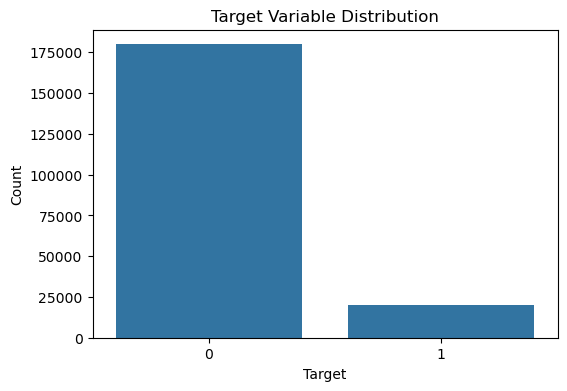

In [10]:
# Visualizing the target distribution
plt.figure(figsize = (6,4))
sns.countplot(x = "target", data = df)
plt.title("Target Variable Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

## Checking the Data Types

In [11]:
# Display data tyes
df.dtypes

ID_code     object
target       int64
var_0      float64
var_1      float64
var_2      float64
            ...   
var_195    float64
var_196    float64
var_197    float64
var_198    float64
var_199    float64
Length: 202, dtype: object

## Data Preprocessing

The ID_code column is only an identifier and does not contribute to prediction. Therofore, it is removed.

In [12]:
# Removing ID column
df = df.drop("ID_code", axis = 1)

# Display first five rows
df.head()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## Feature Scaling 

Feature scaling standardizes numerical features so they have a similar scale, improving the performance of many machine learning algorithms.

In [13]:
# Feature Scaling
# Separate independent and dependent variables
X = df.drop("target", axis = 1)
Y = df["target"]

# StandardScaler
scaler = StandardScaler()

# Scaling the independent variables
X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed Successfully.")

Feature Scaling Completed Successfully.


## Train-Test Split

In this step, the dataset is split into training and testing sets. The training set is used to train the model, while the testing set is used to evlaute its performance

In [14]:
# Spliting dataset into training and testing sets

X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size = 0.2, random_state = 42)

# Display the shapes
print("X_train Shape :", X_train.shape)
print("X_test Shape  :", X_test.shape)
print("Y_train Shape :", Y_train.shape)
print("Y_test Shape  :", Y_test.shape)

X_train Shape : (160000, 200)
X_test Shape  : (40000, 200)
Y_train Shape : (160000,)
Y_test Shape  : (40000,)


## Logistic Regression Model

Logistic Regression is a supervised machine learning algorithm used for binary classification problems. It predicts whether a customer will make a future transaction or not.

In [15]:
# Logistic Regression Model
# Creating Logistic Regression model

lr_model = LogisticRegression(random_state = 42)
lr_model.fit(X_train, Y_train)
Y_pred_lr = lr_model.predict(X_test)

lr_accuracy = accuracy_score(Y_test, Y_pred_lr)
print("Logistic Regression Accuracy :", lr_accuracy)

Logistic Regression Accuracy : 0.913075


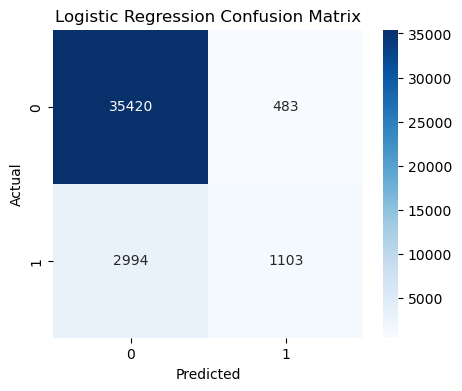

In [47]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_lr)

plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
# Classification Report
print(classification_report(Y_test, Y_pred_lr))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35903
           1       0.70      0.27      0.39      4097

    accuracy                           0.91     40000
   macro avg       0.81      0.63      0.67     40000
weighted avg       0.90      0.91      0.90     40000



## Decision Tree Classifier

Decision Tree creates a tree-like structure to classify customer transaction based on feature values.

In [18]:
print(X_train.shape)
print(Y_train.shape)
print(type(X_train))
print(type(Y_train))

(160000, 200)
(160000,)
<class 'numpy.ndarray'>
<class 'pandas.core.series.Series'>


In [19]:
# Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth = 10,random_state = 42)

In [20]:
dt_model.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [21]:
Y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(Y_test, Y_pred_dt)
print("Decision Tree Accuracy :", dt_accuracy)

Decision Tree Accuracy : 0.892825


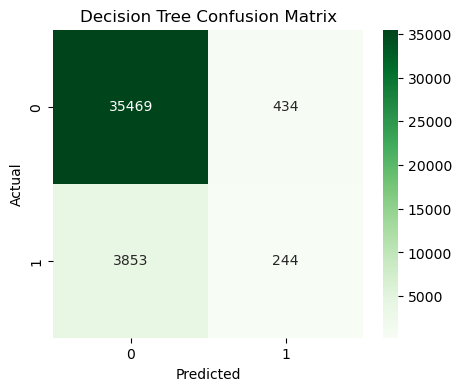

In [22]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_dt)

plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Greens')
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [23]:
# Classification Report
print(classification_report(Y_test, Y_pred_dt))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94     35903
           1       0.36      0.06      0.10      4097

    accuracy                           0.89     40000
   macro avg       0.63      0.52      0.52     40000
weighted avg       0.85      0.89      0.86     40000



## Random Forest Classifier

Random Forest combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [24]:
# Random Forest Classifier
rf_model = RandomForestClassifier(max_depth = 10,min_samples_split = 50, min_samples_leaf = 20, random_state=42)

In [ ]:
rf_model.fit(X_train, Y_train)

In [26]:
Y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(Y_test, Y_pred_dt)
print("Random Forest Accuracy :", rf_accuracy)

Random Forest Accuracy : 0.892825


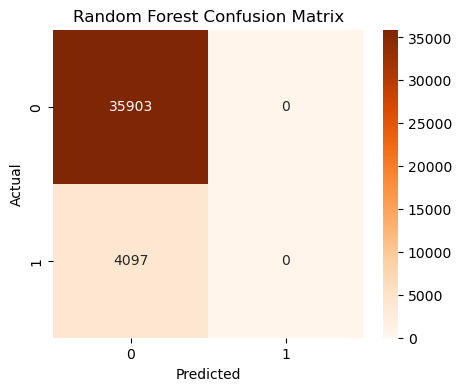

In [27]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_rf)

plt.figure(figsize = (5,4))
sns.heatmap(cm,annot = True, fmt = "d", cmap = "Oranges")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [28]:
# Classification Report
print(classification_report(Y_test,Y_pred_dt))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94     35903
           1       0.36      0.06      0.10      4097

    accuracy                           0.89     40000
   macro avg       0.63      0.52      0.52     40000
weighted avg       0.85      0.89      0.86     40000



## XGBoost Classifier

XGBoost is an advanced boosting algorithm that builds trees sequentially to improve prediction accuracy.

In [29]:
# XGBoost Classifier
xgb_model = XGBClassifier(max_depth = 10,random_state = 42)

In [30]:
xgb_model.fit(X_train,Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [31]:
Y_pred_xgb = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(Y_test, Y_pred_xgb)
print("XGBoost Accuracy :", xgb_accuracy)

XGBoost Accuracy : 0.90555


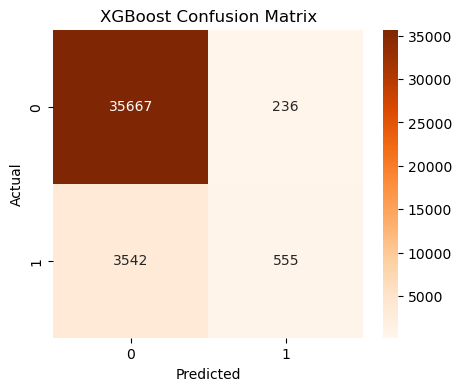

In [32]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_xgb)

plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Oranges")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [33]:
# Classification Report
print(classification_report(Y_test, Y_pred_xgb))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95     35903
           1       0.70      0.14      0.23      4097

    accuracy                           0.91     40000
   macro avg       0.81      0.56      0.59     40000
weighted avg       0.89      0.91      0.88     40000



## LightGBM Classifier

LightGBM is a fast gradient boosting algorithm designed for lare datasets.

In [34]:
# LightGBM Classifier
lgbm_model = LGBMClassifier(max_depth = 10, random_state = 42)

In [35]:
lgbm_model.fit(X_train, Y_train)

[LightGBM] [Info] Number of positive: 16001, number of negative: 143999
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.288457 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 51000
[LightGBM] [Info] Number of data points in the train set: 160000, number of used features: 200
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.100006 -> initscore=-2.197155
[LightGBM] [Info] Start training from score -2.197155


LGBMClassifier(max_depth=10, random_state=42)

In [36]:
Y_pred_lgbm = lgbm_model.predict(X_test)

lgbm_accuracy = accuracy_score(Y_test, Y_pred_lgbm)
print("LightGBM Accuracy :", lgbm_accuracy)

LightGBM Accuracy : 0.906125


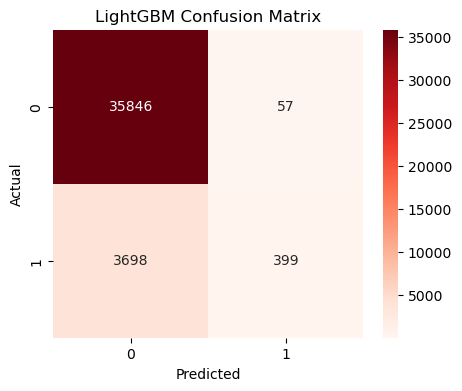

In [37]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_lgbm)

plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Reds")
plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [38]:
# Classification Report
print(classification_report(Y_test, Y_pred_lgbm))

              precision    recall  f1-score   support

           0       0.91      1.00      0.95     35903
           1       0.88      0.10      0.18      4097

    accuracy                           0.91     40000
   macro avg       0.89      0.55      0.56     40000
weighted avg       0.90      0.91      0.87     40000



## CatBoost Classifier

CatBoost is a boosting algorithm that performs well on many classification problems and requries minimal preprocessing

In [39]:
# CatBoost Classifier
cat_model = CatBoostClassifier(verbose = 0, random_state = 42)

In [50]:
cat_model.fit(X_train, Y_train)

CatBoostClassifier(random_state=42, verbose=0)

In [51]:
Y_pred_cat = cat_model.predict(X_test)

cat_accuracy = accuracy_score(Y_test, Y_pred_cat)
print("CatBoost Accuracy :", cat_accuracy)

CatBoost Accuracy : 0.92265


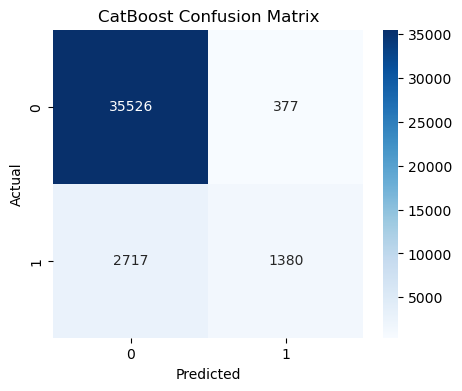

In [52]:
# Confusion Matrix
cm = confusion_matrix(Y_test, Y_pred_cat)

plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = "d", cmap = 'Blues')
plt.title("CatBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Classification Report
print(classification_report(Y_test, Y_pred_cat))

## Model Comparision

In this section we compares the performance of all trained machine learning models. The model with the highest accuracy will be identified as the best model.

In [44]:
# Model Comparision
comparison = pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "LightGBM", "CatBoost"],
                           "Accuracy" : [lr_accuracy, dt_accuracy, rf_accuracy, xgb_accuracy, lgbm_accuracy, cat_accuracy]})
comparison = comparison.sort_values(by = "Accuracy", ascending = False)
print(comparison)

                 Model  Accuracy
5             CatBoost  0.922650
0  Logistic Regression  0.913075
4             LightGBM  0.906125
3              XGBoost  0.905550
1        Decision Tree  0.892825
2        Random Forest  0.892825


## Best Model Selection

In this section selecting the best-performing model based on accuracy.

In [54]:
# Best Model Slection
best_model = comparison.iloc[0]

print("Best Model :", best_model["Model"])
print("Accuracy :", best_model["Accuracy"])

Best Model : CatBoost
Accuracy : 0.92265


## Saving the Best Model

In this section saves the trained model so it can be used later without retraining .

In [55]:
# Saving the Best Model

joblib.dump(cat_model, "Customer_transaction_prediction_model.pkl")
print("Model Saved Successfully.")

Model Saved Successfully.


## Loading the Saved Model 

In this section loading the saved model. 

In [56]:
# Loading the Saved Model

loaded_model = joblib.load("Customer_transaction_prediction_model.pkl")

print("Model Loaded Successfully.")

Model Loaded Successfully.


## Prediction Using Loaded Model

In this section uses the loaded model to predict customer transactions on sample data.

In [58]:
# Prediction Using Loaded Model

sample_prediction = loaded_model.predict(X_test[:6])

print("Predicted Values :", sample_prediction)
print("Actual Values :", Y_test[:6].values)

Predicted Values : [0 0 0 0 1 0]
Actual Values : [0 0 0 0 1 0]


## Conclusion

In [59]:
# Project Completion
print("Customer Transaction Prediction Project Completed Successfully.")

Customer Transaction Prediction Project Completed Successfully.


## Model Comparison Report

The performance of six machine learning classification algorithms was compared using the accuracy metric.

## Model Comparison Report

| Model | Accuracy |
|--------|----------|
| Logistic Regression | 0.913075 |
| Decision Tree |  0.892825 |
| Random Forest |  0.892825 |
| XGBoost | 0.905550 |
| LightGBM | 0.906125 |
| CatBoost |  0.922650 |

### Conclusion

CatBoost achieved the highest accuracy and is recommended for production because it provides better prediction performance than the other models.

## Report On Challenges Faced

#### Challenges Faced

#### Techniques Used